# Lab 0 - Synthetic data generation

This lab is about the generation of synthetic data.

How to generate this data depends on the learning task: **classification** or **regression**.

In [1]:
# import libraries
%matplotlib inline
import numpy as np
import matplotlib as cm
import matplotlib.pyplot as plt
import os

### Reproducibility note

Synthetic datasets change at every run because they rely on random sampling. During debugging or when comparing results, it can be useful to set a seed, e.g. `np.random.seed(0)`. Remove or change the seed when you want to observe different random realizations.

In [2]:
# Optional: uncomment for reproducible results
np.random.seed(0)

## Generating data for regression problems

Let's define a function to generate a D-dimensional dataset according to a linear regression problem, possibly affected by Gaussian noise.
The use of the function is the following:

```
X, Y = linearRegrFunction(n, d, low_d, high_d, w, sigma_noise)
```

where
- **n** is the number of samples to be generated
- **d** is the size of each sample
- **low_d** and **high_d** are arrays of, respectively, lower and upper bounds for the domain of the samples
- **w** is an array with the linear function coefficients
- **sigma_noise** is the standard deviation used to generate the Gaussian noise (with zero mean)
- **X**, **Y**: d-dimensional samples (X) associated with 1-dimensional output (Y)


In [3]:
def linearRegrFunction(n, d, low_d, high_d, w, sigma_noise):
    """Generate samples from a linear regression model Y = Xw + noise."""
    X = np.zeros((n, d))
    for i in range(d):
        X[:, i] = np.random.uniform(low_d[i], high_d[i], size=n)

    # Keep both the linear prediction and the noise one-dimensional.
    # This avoids unintended broadcasting between shapes (n,) and (n, 1).
    w = np.asarray(w).reshape(-1)
    gauss_noise = np.random.normal(0, sigma_noise, size=n)
    Y = X @ w + gauss_noise

    return X, Y

### Play with the data generator

To start, generate a dataset of 1-dimensional input, for different values of `w` and no noise. <br> Pick the bounds of the domain that you prefer. 
<br> Let's consider the function `Y = wX` with `w=1` (the identity function), and then change the value of `w` as you prefer

**Notice that since no noise is added, the obtained samples refer to the TRUE function**

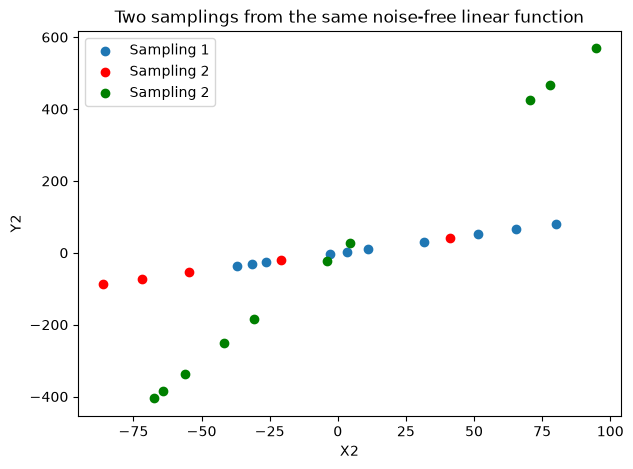

In [23]:
w = np.array([1])
d = 1
low_d = np.array([-100])
high_d = np.array([100])

n = 10
X, Y = linearRegrFunction(n, d, low_d, high_d, w, 0)

plt.figure(figsize=(7, 5))
plt.scatter(X, Y, label="Sampling 1")

# TODO 1: generate a second sampling using exactly the same parameters.
# TODO 2: visualize it on the same plot using a different marker.
X1, Y1 = linearRegrFunction(5, d,low_d, high_d, w,0)
plt.scatter(X1, Y1, label="Sampling 2",c='red')

X2,Y2=linearRegrFunction(10,d,low_d,high_d,6,0)
plt.scatter(X2, Y2, label="Sampling 2",c='green')

plt.xlabel("X")
plt.ylabel("Y")
plt.xlabel("X1")
plt.ylabel("Y1")
plt.xlabel("X2")
plt.ylabel("Y2")
plt.title("Two samplings from the same noise-free linear function")
plt.legend()
plt.show()

# QUESTION: what changes if you increase n? What changes if you modify w?

### Time to add noise

- Still considering the 1-dimensional case, fix the linear coefficients, the bounds, the number of samples and the amount of noise (e.g. `sigma_noise=3`) and generate multiple instances of the data.
- Plot them together and observe the relationship between the different samples sets.
- Also, generate the "TRUE" function and plot its samples as well. 

**Hint:** A sensible amount of noise depends on the `low_d` and `high_d` bounds!

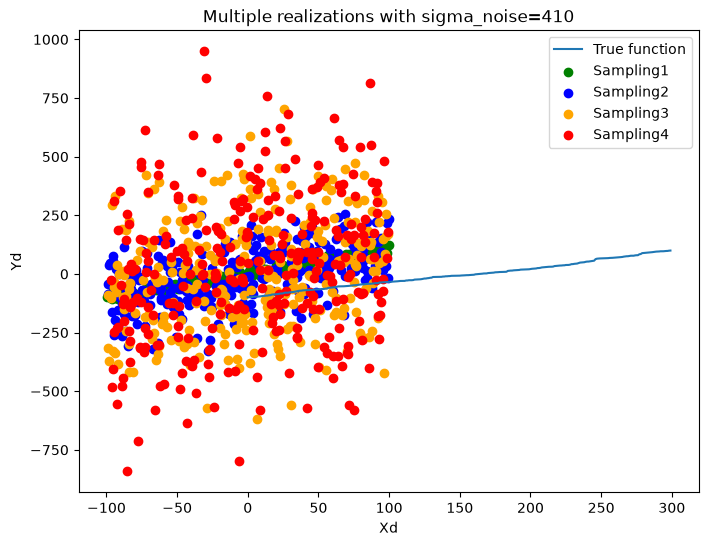

In [40]:
w = np.array([1])
D = 1
low_D = np.array([-100])
high_D = np.array([100])

n = 30
sigma_noise1 = 10

# Generate a dense noise-free sample of the true function.
Xtrue, Ytrue = linearRegrFunction(300, D, low_D, high_D, w, 0)

# TODO 1: sort the points according to X before using plt.plot,
# so that the true function is visualized as a line rather than as a zig-zag.
order = sorted(Xtrue)

plt.figure(figsize=(8, 6))
plt.plot(order, label='True function')

# TODO 2: generate 4 different noisy datasets using the SAME parameter values.
# Plot them on the same axes using scatter and compare the realizations.
colors = ["green", "blue", "orange", "red"]
for i in range(4):
    Xd, Yd = linearRegrFunction(300,D,low_d,high_d,w,sigma_noise1)
    sigma_noise1+=100
    plt.scatter(Xd, Yd, label=f"Sampling{i+1}",c=colors[i])

plt.xlabel('X')
plt.ylabel('Y')
plt.xlabel('Xd')
plt.ylabel('Yd')
plt.title(f'Multiple realizations with sigma_noise={sigma_noise1}')
plt.legend()
plt.show()

### Change the amount of noise 

- Again on the 1-dimensional case, fix the parameters of the function, the bounds, the number of samples and compare the data obtained according to different amount of noise. <br>
- Plot them together and observe the relationship between the different samples sets. <br>
- Observe the difference as you change also the number of samples
- Also, generate the "TRUE" function and plot its samples as well. 

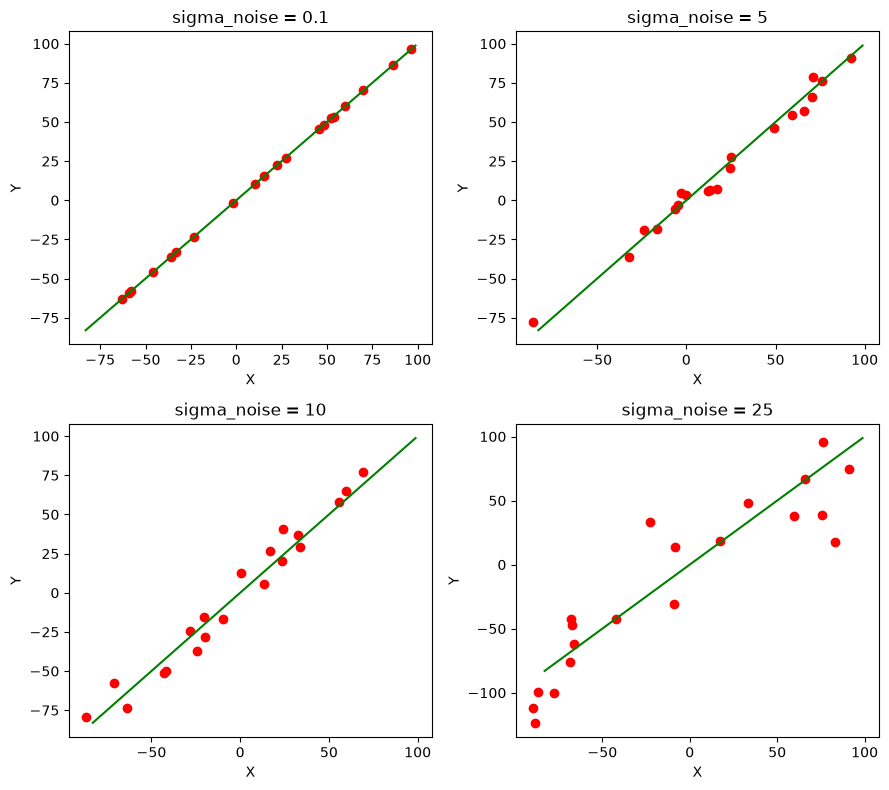

In [48]:
n = 10
D = 1
w = np.array([1])

low_D = np.array([-100])
high_D = np.array([100])

# Compute samples from the true function.
Xtrue, Ytrue = linearRegrFunction(30, D, low_D, high_D, w, 0)
order = np.argsort(Xtrue[:, 0])

# Compare four different noise levels.
fig = plt.figure(figsize=(9, 8))
axes = [fig.add_subplot(2, 2, i + 1) for i in range(4)]
noise_levels = [0.1, 5, 10, 25]

for ax, sigma in zip(axes, noise_levels):
    # TODO 1: generate n samples with the current value of sigma.
    Xd, Yd = linearRegrFunction(20,D,low_d,high_d,w,sigma)

    # TODO 2: plot the true function and the noisy samples on the same axes.
    ax.plot(Xtrue[order],Ytrue[order],label='Xtrue',c='green')
    ax.scatter(Xd,Yd, label='XDYD', c='red')

    ax.set_title(f'sigma_noise = {sigma}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

fig.tight_layout()

# FURTHER EXPERIMENT: repeat with a smaller and a larger value of n.
# Which visual effect is due to noise, and which one is due to sample size?

### Regression with 2D input

- Let us now consider a sample set with 2D input and 1D output. Fix the parameters of the function, the bounds and the number of samples, and compare the data obtained with different amounts of noise.
- Plot the datasets together with samples from the **true** function.
- Observe what changes when the noise level increases.
- As a further experiment, change the number of samples and compare the resulting point clouds.

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

n = 100
D = 2
w = np.array([0, 0])

low_D = np.array([-100, -100])
high_D = np.array([100, 100])

# Samples from the true function.
Xtrue, Ytrue = linearRegrFunction(n, D, low_D, high_D, w, 0)

fig = plt.figure(figsize=(10, 10))
axes = [fig.add_subplot(2, 2, i + 1, projection='3d') for i in range(4)]
noise_levels = [0.1, 5, 10, 25]

for ax, sigma in zip(axes, noise_levels):
    # TODO 1: generate a noisy 2D-input regression dataset.
    Xd, Yd = ...

    # TODO 2: visualize the true-function samples and the noisy samples in 3D.
    # Hint: use X[:,0], X[:,1], Y as the three coordinates.
    # ax.scatter(...)
    # ax.scatter(...)

    ax.set_title(f'sigma_noise = {sigma}')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('Y')

fig.tight_layout()

# FURTHER EXPERIMENTS:
# 1. Change n and observe the effect of sample size.
# 2. Try a non-zero vector, e.g. w = [0.5, -0.3]. What changes geometrically?

## Generating data for classification problems

Let us play with the generation of 2D datasets for binary classification problems. We start by definying a function to generate datasets using 2D Gaussians.
The use of the function is the following:
##### X, Y = mixGauss(means, sigmas, n)
where
- <b>means</b> refers to the means of the Gaussian functions. It is in the form [m1,...mp], where p is the number of classes/Gaussian, and each mi is D-dimensional (e.g. D=2 for 2D data)  
- <b>sigmas</b> refers to the standard deviations of the Gaussian functions. It is in the form [s1,...sp], where p is the number of classes/Gaussian (we assume standard deviation is the same for all dimensions)
- <b>n</b> is the number of points for each class
- <b>X</b>, <b>Y</b>: D-dimensional samples (X) associated with 1-dimensional output (Y). The latter is an array of labels, i.e. integers from the interval [0,p-1]
<br>

<b>EXAMPLE</b>: 

```X, Y = MixGauss([[0,0],[1,1]],[0.5, 0.25],1000)```

generates a 2D dataset with two classes
- the first one centered on (0,0) with standard deviation 0.5
- the second one centered on (1,1) with standard deviation 0.25.
Each class will contain 1000 points.

In [ ]:
def mixGauss(means, sigmas, n):

    means = np.array(means)
    sigmas = np.array(sigmas)

    d = means.shape[1]
    num_classes = sigmas.size
    data = np.full((n * num_classes, d), np.inf)
    labels = np.zeros(n * num_classes)

    for idx, sigma in enumerate(sigmas):
        data[idx * n:(idx + 1) * n] = np.random.multivariate_normal(mean=means[idx], cov=np.eye(d) * sigmas[idx] ** 2,
                                                                    size=n)
        labels[idx * n:(idx + 1) * n] = idx 
        
    if(num_classes == 2):
        labels[labels==0] = -1

    return data, labels

### Play with the data generator
Try and generate different datasets, by changing the parameters of the Gaussians

In [ ]:
# Setup a plot in which the different datasets can be visually compared.
fig = plt.figure(figsize=(9, 8))
ax0 = fig.add_subplot(2, 2, 1)
ax1 = fig.add_subplot(2, 2, 2)
ax2 = fig.add_subplot(2, 2, 3)
ax3 = fig.add_subplot(2, 2, 4)

# Dataset 1: two Gaussians centered at (0,0) and (1,1),
# both with standard deviation 0.25.
X1d, Y1d = mixGauss([[0, 0], [1, 1]], [0.25, 0.25], 100)
ax0.set_title("Dataset 1")
ax0.scatter(X1d[:, 0], X1d[:, 1], s=45, c=Y1d, alpha=0.8)

# TODO: create three further binary datasets by changing the Gaussian parameters.
# Keep n=100 for an easier visual comparison.
# Suggested progression:
#   Dataset 2 -> move the class centers farther apart
#   Dataset 3 -> increase the standard deviations
#   Dataset 4 -> use asymmetric centers and/or different standard deviations

X2d, Y2d = ...
# ax1.scatter(...)
ax1.set_title("Dataset 2")

X3d, Y3d = ...
# ax2.scatter(...)
ax2.set_title("Dataset 3")

X4d, Y4d = ...
# ax3.scatter(...)
ax3.set_title("Dataset 4")

for ax in [ax0, ax1, ax2, ax3]:
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')

fig.tight_layout()

# QUESTION: which change affects class overlap more: moving the means or increasing sigma?

## Adding noise to the binary classification dataset

So far no noise has been added to the dataset. Let's add some using the function <b>flipLabels</b> that flips randomly selected labels of a binary classification problem. The use is the following

##### Y_noisy = flipLabels(Y, perc)
where
- <b>Y</b> is the array of labels 
- <b>perc</b> is the percentage of labels to be flipped
- <b>Y_noisy</b> is the array including the flipped labels 

In [ ]:
def flipLabels(Y, perc):
    """Flip a given percentage of labels in a binary {-1,+1} problem."""
    if perc < 0 or perc > 100:
        print("perc should be a percentage value between 0 and 100.")
        return -1

    Y_noisy = np.copy(np.squeeze(Y))
    if Y_noisy.ndim != 1:
        print("Please supply a label array with only one dimension")
        return -1

    if np.any(np.abs(Y_noisy) != 1):
        print("The values of Y should be +1 or -1.")
        return -1

    n = Y_noisy.size
    n_flips = int(np.floor(n * perc / 100))
    idx_to_flip = np.random.choice(n, size=n_flips, replace=False)
    Y_noisy[idx_to_flip] = -Y_noisy[idx_to_flip]

    return Y_noisy

### Play with the noise in 2D datasets for binary classification
Try and generate different datasets in which all parameters but the amount of noise are fixed. See what happens when you increase the percentage of flipped labels

In [ ]:
X1, Y1 = mixGauss([[0, 0], [1, 1]], [0.25, 0.25], 100)

fig = plt.figure(figsize=(9, 8))
axes = [fig.add_subplot(2, 2, i + 1) for i in range(4)]
flip_percentages = [5, 10, 30, 50]

for ax, perc in zip(axes, flip_percentages):
    # TODO 1: flip perc percent of the labels.
    Y_noisy = ...

    # TODO 2: visualize the same input points using the noisy labels.
    ax.set_title(f"Flipping {perc}% labels")
    # ax.scatter(...)
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')

fig.tight_layout()

# QUESTION: how is label noise different from increasing the overlap between the two Gaussians?

### Generate a more complex dataset with Gaussians

Let's generate a more complex binary dataset. To do it, follow the instructions below:
- Call the function *mixGauss* and produce a 2D dataset with 4 classes: the classes must be centered on the corners of the unit square `(0,0)`, `(0,1)`, `(1,1)`, `(1,0)`, and all of them have standard deviation equal to 0.25.
- Plot the obtained dataset.
- Manipulate the labels to obtain a 2-class problem where data on opposite corners belong to the same class, with labels `+1` and `-1`.

**Hint:** since the four original labels are `0,1,2,3`, their parity can be used to group opposite corners. One possible transformation is `Y2 = 2 * np.mod(Y4, 2) - 1`.

In [ ]:
# TODO 1: generate four Gaussian classes centered on the corners
# of the unit square: (0,0), (0,1), (1,1), (1,0).
# Use standard deviation 0.25 for all classes and 100 samples per class.
X, Y4 = ...

fig = plt.figure(figsize=(10, 7))
ax0 = fig.add_subplot(1, 2, 1)
ax1 = fig.add_subplot(1, 2, 2)

ax0.set_title("Dataset 1 - 4 classes")
# ax0.scatter(...)

# TODO 2: transform the four labels into two labels {-1,+1}
# so that opposite corners belong to the same class.
# Hint: exploit whether the original class index is even or odd.
Y2 = ...

ax1.set_title("Dataset 2 - 2 classes")
# ax1.scatter(...)

plt.tight_layout()

### A different way of generating binary classification problems: using a separator

Let's explore different strategies to generate datasets for binary classification, based on the concept of separators. 

Observe what happens as you change the number of sampled points

In [ ]:
n = 200 # number of points per class
D = 2 # dimension of the points

# linear case
m = 0.9
q = 0

# bounds (assume they are the same for all dimensions)
low_D = -10
high_D = 10

X = np.zeros((n, D))
Y = np.zeros(n)

# sampling of the X
for i in range(D):
    X[:,i] = np.random.uniform(low_D, high_D, size=n)
    
# assigning the labels depending on the position of the sample with respect to the linear separator
Y[X[:,1] - (X[:,0] * m + q) > 0] = 1 
Y[Y==0] = -1

# add some noise
Yn = flipLabels(Y, 10)

# plot the samples and the separator
plt.title("Linear, 10% flipped labels")
plt.scatter(X[:,0], X[:,1], s=70, c=Yn, alpha=0.8)
plt.plot(X[:,0], X[:,0] * m + q)
plt.xlim((low_D, high_D))
plt.ylim((low_D, high_D))
